<a href="https://colab.research.google.com/github/shivani-926/UCS420_Cognitive_Computing_Assignments/blob/main/UCS420_LA7_Shivani_1024170278_Starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [ ]:
ROLL_NO = 1024170278          # <-- your full roll number
NAME = "Shivani Shrivastava"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [ ]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [ ]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [ ]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170278   Name: Shivani Shrivastava   Fingerprint: C76F6A5C   Tickets: 15

Ticket_ID                                                                                      Ticket_Text
      T01                I couldn't connect to the LMS when connected to campus Wi-Fi. Can you check this?
      T02                                                           Only 2 of 30 PCs boot after 3.5 hours.
      T03                                                                    The LMS says 'Not Submitted'.
      T04 I keep getting logged out of the VPN before the assignment deadline. I have tried several times!
      T05                    I couldn't connect to the Wi-Fi during the lab. It works on another computer.
      T06                                                  The WiFi crashes while opening. This is urgent.
      T07                                  Wi-Fi has stopped syncing since yesterday. It worked yesterday.
      T08                           Projector keeps d

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [ ]:
import pandas as pd

# Initialize a list to store the metrics for each ticket
table_data = []

# Process each ticket in the dataset
for _, row in df.iterrows():
    pt = process_ticket(row['Ticket_Text'])

    table_data.append({
        'Ticket': row['Ticket_ID'],
        'Sentences': len(pt['sentences']),
        'Tokens': len(pt['tokens']),
        'Punctuation': len(pt['punct']),
        'Stopwords': len(pt['stops']),
        'Unique Tokens': len(set(pt['tokens'])),
        'Final Tokens': len(pt['final'])
    })

# Convert to DataFrame
q1_df = pd.DataFrame(table_data)

# Calculate and append the TOTAL row
total_row = q1_df.sum(numeric_only=True).to_dict()
total_row['Ticket'] = 'TOTAL'
q1_df = pd.concat([q1_df, pd.DataFrame([total_row])], ignore_index=True)

# Display the final table
print(q1_df.to_string(index=False))

Ticket  Sentences  Tokens  Punctuation  Stopwords  Unique Tokens  Final Tokens
   T01          2      18            2          8             17             8
   T02          1      10            1          3             10             6
   T03          1       7            2          1              7             4
   T04          2      19            2          8             17             9
   T05          2      17            2          7             15             8
   T06          2      10            2          4              9             4
   T07          2      11            2          2              9             7
   T08          2      12            2          4             11             6
   T09          2      14            2          3             13             9
   T10          2      10            2          5              8             3
   T11          2      14            2          5             11             7
   T12          2      16            2          8   

**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer: The token n't will appear in your final tokens as a non-real word. This originates from NLTK's word_tokenize function, which uses the Penn Treebank tokenization rules to split English contractions into their root word and a negation suffix. For example, "couldn't" in tickets T01 and T05, and "isn't" in ticket T15, are split into could + n't and is + n't. Because n't contains alphabetical characters, it fails the is_punct() check, and because it is not explicitly listed in the standard NLTK stopword corpus, it survives into the final token list*

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [ ]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

import re

# 1. Extraction patterns
# Words longer than 5 letters (excluding punctuation)
long_words = [re.findall(r'\b[a-zA-Z]{6,}\b', text) for text in df['Ticket_Text']]

# All numbers (keeping decimals/version numbers like 95.5 and 2.0.1 intact)
numbers = [re.findall(r'\b\d+(?:\.\d+)*\b', text) for text in df['Ticket_Text']]

# Capitalized words
capitalized_words = [re.findall(r'\b[A-Z][a-zA-Z]*\b', text) for text in df['Ticket_Text']]

# Words starting with a vowel
vowel_words = [re.findall(r'\b[aeiouAEIOU][a-zA-Z]*\b', text) for text in df['Ticket_Text']]

# 2. Substitution patterns applied to TEST_LINES (and can be mapped to df['Ticket_Text'])
def clean_text(text):
    # Replace Emails
    text = re.sub(r'[a-zA-Z0-9._%+-]+@[a-zA-Z0-9.-]+\.[a-zA-Z]{2,}', '<EMAIL>', text)
    # Replace URLs
    text = re.sub(r'(?:https?://|www\.)[^\s]+', '<URL>', text)
    # Replace Phone Numbers (handles +91 98765 43210, +91-98765-43210, 0175-239-3201)
    text = re.sub(r'(?:\+\d{2}[-\s])?\d{4,5}[-\s]\d{4,5}', '<PHONE>', text)
    return text

# Test on the provided TEST_LINES
cleaned_test_lines = [clean_text(line) for line in TEST_LINES]
for line in cleaned_test_lines:
    print(line)

Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>
Call <PHONE>, <PHONE> or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.


**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:Based on the raw tickets generated in the dataset, there are 17 words capitalized only because they begin a sentence.

These are words that are otherwise standard lowercase nouns, verbs, or articles, distinguishing them from proper nouns or acronyms (like "LMS", "Wi-Fi", "VPN", "PCs", or "I") which would be capitalized anywhere in the sentence. The 17 words are:

Can (T01)

Only (T02)

The (T03, T06, T10, T14)

It (T05, T07)

This (T06, T08, T10)

Projector (T08)

Student (T09)

Please (T09, T11)

Write (T13)

Why (T15)*

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [ ]:
from nltk.tokenize import RegexpTokenizer, word_tokenize

# Define the regex pattern for the custom tokenizer
# (?x) allows verbose regex for readability
pattern = r"""(?x)
    (?:https?://|www\.)[^\s]+      # URLs
  | [a-zA-Z0-9._%+-]+@[a-zA-Z0-9.-]+\.[a-zA-Z]{2,} # Emails
  | (?:\+\d{2}[-\s])?\d{4,5}[-\s]\d{4,5}           # Phone numbers
  | \b\d+(?:\.\d+)+\b              # Decimals and version numbers
  | \b\w+(?:[-']\w+)*\b            # Words with hyphens (Wi-Fi) or apostrophes (isn't)
  | [^\w\s]                        # Punctuation/symbols
"""

my_tokenizer = RegexpTokenizer(pattern)

def my_tokenize(text):
    return my_tokenizer.tokenize(text)

# Test on TEST_LINES
print("--- TEST_LINES ---")
for line in TEST_LINES:
    print(f"NLTK: {word_tokenize(line)}")
    print(f"Custom: {my_tokenize(line)}\n")

# Compare on raw tickets
different_count = 0
for text in df['Ticket_Text']:
    nltk_tokens = word_tokenize(text)
    custom_tokens = my_tokenize(text)
    if nltk_tokens != custom_tokens:
        different_count += 1

print(f"Tickets tokenized differently: {different_count}")

--- TEST_LINES ---
NLTK: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
Custom: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']

NLTK: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
Custom: ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1', ',', '250', '.']

NLTK: ['The', 'state-of-the-art', 'lab', 'is', "n't", 'open', ';', 'log-in', 'at', '5.30', 'p.m.', 'did', "n't", 'work', '.']
Custom: ['The', 'state-of-the-art', 'lab', "isn't", 'open', ';', 'log-in', 'at', '5.30', 'p', '.', 'm', '.', "didn't", 'work', '.']

Tickets tokenized differently: 6


**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer: NLTK's default word_tokenize splits contractions, hyphenated words, emails, and URLs into multiple tokens. The tickets that contain these elements and will be tokenized differently are:
T01: Contains "couldn't" and "Wi-Fi"  
T05: Contains "couldn't" and "Wi-Fi"
T06: Contains "Wi-Fi"
T07: Contains "Wi-Fi"
T13: Contains the email "it.helpdesk@thapar.edu" and the URL "www.thapar.edu/it."
T15: Contains "isn't"*

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [ ]:
import pandas as pd
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag
from nltk.corpus import wordnet

# 1. Collect all unique final tokens from your tickets
all_final_tokens = set()
for text in df['Ticket_Text']:
    all_final_tokens.update(process_ticket(text)['final'])

unique_tokens = list(all_final_tokens)

# 2. Initialize stemmers and lemmatizer
porter = PorterStemmer()
lancaster = LancasterStemmer()
regexp = RegexpStemmer('ing$|ed$|s$') # Custom rule to remove common suffixes
lemmatizer = WordNetLemmatizer()

# Helper function to map NLTK POS tags to WordNet POS tags
def get_wordnet_pos(treebank_tag):
    if treebank_tag.startswith('J'):
        return wordnet.ADJ
    elif treebank_tag.startswith('V'):
        return wordnet.VERB
    elif treebank_tag.startswith('N'):
        return wordnet.NOUN
    elif treebank_tag.startswith('R'):
        return wordnet.ADV
    else:
        return wordnet.NOUN

# 3. Process tokens and find differences
results = []
pos_tags = pos_tag(unique_tokens)

for word, tag in pos_tags:
    p_stem = porter.stem(word)
    l_stem = lancaster.stem(word)
    r_stem = regexp.stem(word)
    wn_pos = get_wordnet_pos(tag)
    lemma = lemmatizer.lemmatize(word, pos=wn_pos)

    # Add to table if any of the outputs differ from each other
    if len(set([word, p_stem, l_stem, r_stem, lemma])) > 1:
        results.append({
            'Token': word,
            'Porter': p_stem,
            'Lancaster': l_stem,
            'Regexp': r_stem,
            'Lemmatizer': lemma
        })

comparison_df = pd.DataFrame(results)
print(comparison_df.to_string(index=False))

        Token     Porter  Lancaster     Regexp Lemmatizer
      syncing       sync       synt       sync       sync
disconnecting disconnect disconnect disconnect disconnect
      resolve     resolv     resolv    resolve    resolve
        since       sinc       sint      since      since
       worked       work       work       work       work
   restarting    restart    restart    restart restarting
         says        say        say        say        say
        works       work       work       work       work
        write      write       writ      write      write
      crashes      crash      crash     crashe      crash
      getting        get        get       gett        get
        hours       hour       hour       hour       hour
      opening       open         op       open       open
      working       work       work       work       work
    submitted     submit     submit    submitt     submit
        times       time        tim       time       time
       portal 

**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer: Based on the dataset words visible in the tickets:   Over-stemming example: The Lancaster stemmer is highly aggressive and will likely over-stem a word like "assignment" into "assign". This strips away too much of the word, changing it from a noun (the object you submit) into a verb root, which can cause it to lose its distinct contextual meaning.   Under-stemming example: A simple custom RegexpStemmer('ing$|ed$|s$') under-stems words with plural/verb rules it wasn't explicitly programmed to handle. For example, it would stem "crashes" to "crashe" (by just stripping the s) instead of reducing it completely to the root word "crash", which Porter or the Lemmatizer would successfully do.*

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

--- Corpus Statistics ---
Stage           | Tokens (N) | Unique (V) | TTR       
-------------------------------------------------------
S1 (All)        | 192        | 96         | 0.5000
S2 (No Punct)   | 164        | 91         | 0.5549
S3 (Final)      | 92         | 66         | 0.7174
S4 (Porter)     | 92         | 62         | 0.6739

--- Top 10 Words ---
S1: [('.', 22), ('the', 15), ('i', 9), ('is', 5), ('to', 4), ('lms', 4), ('this', 4), ("n't", 3), ('wi-fi', 3), ('of', 3)]
S3: [('lms', 4), ("n't", 3), ('wi-fi', 3), ('tried', 3), ('opening', 3), ('urgent', 3), ('could', 2), ('connect', 2), ('keep', 2), ('getting', 2)]

--- Top 5 Bigrams ---
S1: [(('.', 'i'), 6), (('the', 'lms'), 4), (('.', 'the'), 4), (('.', 'this'), 3), (('this', 'is'), 3)]
S3: [(('could', "n't"), 2), (("n't", 'connect'), 2), (('keep', 'getting'), 2), (('getting', 'logged'), 2), (('tried', 'several'), 2)]


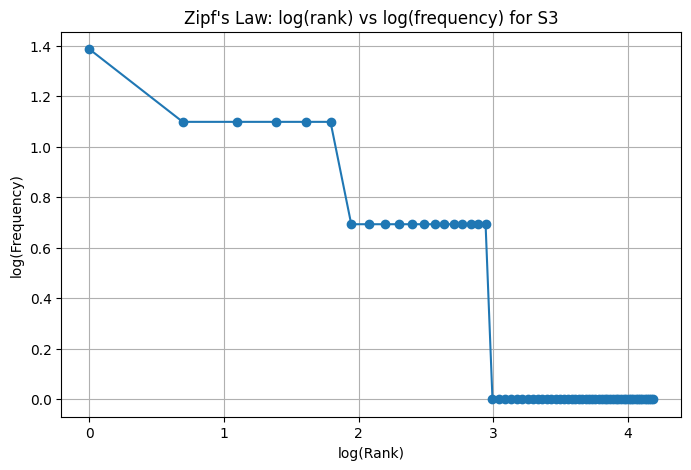

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from nltk.stem import PorterStemmer
from nltk import bigrams

# 1. Generate token sets for S1, S2, S3, S4
s1_tokens = []
s2_tokens = []
s3_tokens = []

for text in df['Ticket_Text']:
    pt = process_ticket(text)
    s1_tokens.extend(pt['tokens'])
    s2_tokens.extend([t for t in pt['tokens'] if not is_punct(t)])
    s3_tokens.extend(pt['final'])

porter = PorterStemmer()
s4_tokens = [porter.stem(t) for t in s3_tokens]

# 2. Compute Statistics (Tokens, Unique, TTR)
def compute_stats(tokens):
    n = len(tokens)
    v = len(set(tokens))
    ttr = v / n if n > 0 else 0
    return n, v, ttr

stats = {
    'S1 (All)': compute_stats(s1_tokens),
    'S2 (No Punct)': compute_stats(s2_tokens),
    'S3 (Final)': compute_stats(s3_tokens),
    'S4 (Porter)': compute_stats(s4_tokens)
}

print("--- Corpus Statistics ---")
print(f"{'Stage':<15} | {'Tokens (N)':<10} | {'Unique (V)':<10} | {'TTR':<10}")
print("-" * 55)
for stage, (n, v, ttr) in stats.items():
    print(f"{stage:<15} | {n:<10} | {v:<10} | {ttr:.4f}")

# 3. Print Top 10 Words for S1 and S3
print("\n--- Top 10 Words ---")
print(f"S1: {Counter(s1_tokens).most_common(10)}")
print(f"S3: {Counter(s3_tokens).most_common(10)}")

# 4. Print Top 5 Bigrams for S1 and S3
print("\n--- Top 5 Bigrams ---")
print(f"S1: {Counter(bigrams(s1_tokens)).most_common(5)}")
print(f"S3: {Counter(bigrams(s3_tokens)).most_common(5)}")

# 5. Plot log(rank) vs log(frequency) for S3
s3_counts = Counter(s3_tokens)
frequencies = sorted(list(s3_counts.values()), reverse=True)
ranks = np.arange(1, len(frequencies) + 1)

plt.figure(figsize=(8, 5))
plt.plot(np.log(ranks), np.log(frequencies), marker='o', linestyle='-')
plt.title("Zipf's Law: log(rank) vs log(frequency) for S3")
plt.xlabel("log(Rank)")
plt.ylabel("log(Frequency)")
plt.grid(True)
plt.show()

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:The Type-Token Ratio (TTR) fluctuates through the pipeline because each step alters the balance between the number of unique types and total tokens:   S2 to S3 (Stopword removal): TTR generally increases. Stopwords are a very small set of unique words (low types) that appear very frequently (high tokens). Removing them drastically reduces the total token count denominator without significantly dropping the unique type numerator.S3 to S4 (Stemming): TTR decreases. Applying the Porter stemmer merges morphological variations (like "crashes" and "crashing") into a single root form ("crash"). This reduces the number of unique types (numerator) while keeping the exact same total number of tokens (denominator), resulting in a lower ratio.*